# Step 06 — Evaluation & Risk Scoring

**Tujuan:** Mengoptimalkan threshold untuk konteks bisnis dan membangun sistem risk scoring yang actionable.

Sampai sini kita punya model yang bagus secara teknis (AUC-ROC ~0.96). Tapi model baru berguna di production kalau bisa menjawab:
- **Threshold berapa** yang optimal untuk bisnis?
- **Berapa biaya** membiarkan fraud lolos (FN) vs memblokir transaksi sah (FP)?
- **Bagaimana mengelompokkan** transaksi ke dalam risk bucket yang actionable?

---

## 6.1 Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, precision_score, recall_score,
    confusion_matrix
)

FRAUD_COLOR    = '#E84C4C'
NONFRAUD_COLOR = '#4C9BE8'
SEED = 42
print('Setup done ✓')

Setup done ✓


In [2]:
%%time
# Load feature matrix
df = pd.read_parquet('../data/features/train_features.parquet')

DROP_COLS    = ['TransactionID', 'isFraud', 'TransactionDT']
feature_cols = [c for c in df.columns if c not in DROP_COLS]
X = df[feature_cols]
y = df['isFraud']

_, X_val, _, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# Load model terbaik
model = joblib.load('../models/artifacts/lgbm_baseline.pkl')
y_prob = model.predict_proba(X_val)[:, 1]

# Load TransactionAmt untuk analisis bisnis
val_idx = X_val.index
amt_val = df.loc[val_idx, 'TransactionAmt'] if 'TransactionAmt' in df.columns else None

print(f'Validation set: {len(y_val):,} transaksi')
print(f'Fraud          : {y_val.sum():,} ({y_val.mean()*100:.2f}%)')
print(f'AUC-ROC        : {roc_auc_score(y_val, y_prob):.4f}')

Validation set: 118,108 transaksi
Fraud          : 4,133 (3.50%)
AUC-ROC        : 0.9609
CPU times: user 7.73 s, sys: 1.71 s, total: 9.44 s
Wall time: 2.82 s


---
## 6.2 Business Context — Asumsi Biaya

Tanpa asumsi biaya yang jelas, threshold 0.5 tidak punya makna bisnis.

**Asumsi (realistik untuk e-commerce fraud prevention):**
- **False Negative (FN):** Fraud yang lolos → kerugian = nilai transaksi penuh
- **False Positive (FP):** Transaksi sah yang diblokir → kehilangan revenue + churn risk
  - Estimated: 10% dari nilai transaksi (lost sale + customer friction)
- **True Positive (TP):** Fraud terdeteksi → kerugian dicegah, biaya review ~$5/transaksi
- **True Negative (TN):** Transaksi sah disetujui → nol biaya

In [3]:
# Asumsi biaya bisnis
FP_COST_RATE = 0.10   # 10% dari amount = biaya memblokir transaksi sah
FN_COST_RATE = 1.00   # 100% dari amount = kerugian fraud lolos
TP_REVIEW_COST = 5.0  # $5 per transaksi fraud yang ditangkap

if amt_val is not None:
    avg_amt = amt_val.mean()
    avg_fraud_amt = amt_val[y_val == 1].mean()
    avg_legit_amt = amt_val[y_val == 0].mean()
    print(f'Rata-rata amount transaksi  : ${avg_amt:.2f}')
    print(f'Rata-rata amount fraud      : ${avg_fraud_amt:.2f}')
    print(f'Rata-rata amount legitimate : ${avg_legit_amt:.2f}')
    print(f'\nAsumsi biaya per transaksi:')
    print(f'  FP cost (avg): ${avg_legit_amt * FP_COST_RATE:.2f}')
    print(f'  FN cost (avg): ${avg_fraud_amt * FN_COST_RATE:.2f}')
    print(f'  TP review   : ${TP_REVIEW_COST:.2f}')
else:
    avg_amt = 150
    avg_fraud_amt = 200
    avg_legit_amt = 140
    print('TransactionAmt tidak tersedia, pakai asumsi rata-rata')

Rata-rata amount transaksi  : $134.85
Rata-rata amount fraud      : $154.64
Rata-rata amount legitimate : $134.13

Asumsi biaya per transaksi:
  FP cost (avg): $13.41
  FN cost (avg): $154.64
  TP review   : $5.00


---
## 6.3 Cost-Sensitive Threshold Optimization

In [4]:
thresholds = np.linspace(0.01, 0.99, 500)

metrics_sweep = []
for thr in thresholds:
    pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    # Business cost
    if amt_val is not None:
        fp_cost = (amt_val.values[pred==1][y_val.values[pred==1]==0] * FP_COST_RATE).sum() if fp > 0 else 0
        fn_cost = (amt_val.values[pred==0][y_val.values[pred==0]==1] * FN_COST_RATE).sum() if fn > 0 else 0
    else:
        fp_cost = fp * avg_legit_amt * FP_COST_RATE
        fn_cost = fn * avg_fraud_amt * FN_COST_RATE

    tp_cost  = tp * TP_REVIEW_COST
    total_cost = fp_cost + fn_cost + tp_cost

    metrics_sweep.append({
        'threshold' : thr,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        'precision' : precision_score(y_val, pred, zero_division=0),
        'recall'    : recall_score(y_val, pred),
        'f1'        : f1_score(y_val, pred, zero_division=0),
        'fp_cost'   : fp_cost,
        'fn_cost'   : fn_cost,
        'total_cost': total_cost,
    })

sweep_df = pd.DataFrame(metrics_sweep)

# Threshold optimal untuk berbagai kriteria
thr_f1     = sweep_df.loc[sweep_df['f1'].idxmax(), 'threshold']
thr_cost   = sweep_df.loc[sweep_df['total_cost'].idxmin(), 'threshold']
thr_recall = sweep_df.loc[sweep_df[sweep_df['precision'] >= 0.7]['recall'].idxmax(), 'threshold'] \
             if (sweep_df['precision'] >= 0.7).any() else thr_f1

print('Threshold optimal per kriteria:')
print(f'  Max F1           : {thr_f1:.4f}')
print(f'  Min Business Cost: {thr_cost:.4f}')
print(f'  Max Recall @ P≥70%: {thr_recall:.4f}')

Threshold optimal per kriteria:
  Max F1           : 0.2476
  Min Business Cost: 0.0925
  Max Recall @ P≥70%: 0.1435


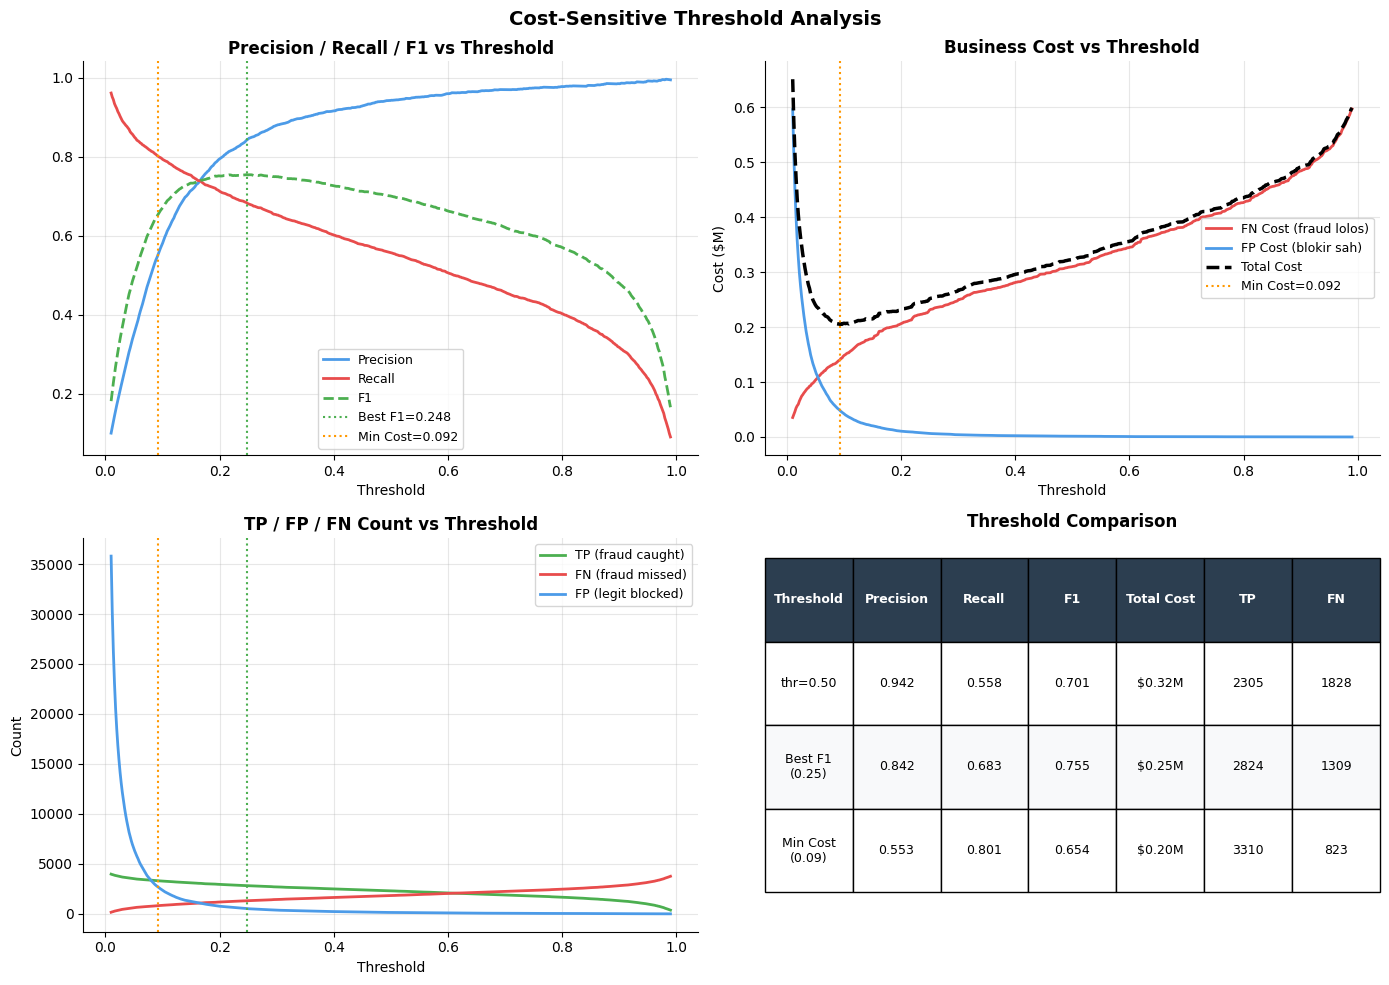


Threshold bisnis terpilih: 0.0925 (min total cost)


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Precision/Recall/F1 sweep ---
ax = axes[0, 0]
ax.plot(sweep_df['threshold'], sweep_df['precision'], color=NONFRAUD_COLOR, linewidth=2, label='Precision')
ax.plot(sweep_df['threshold'], sweep_df['recall'],    color=FRAUD_COLOR,    linewidth=2, label='Recall')
ax.plot(sweep_df['threshold'], sweep_df['f1'],        color='#4CAF50',      linewidth=2, label='F1', linestyle='--')
ax.axvline(thr_f1,   color='#4CAF50', linestyle=':', linewidth=1.5, label=f'Best F1={thr_f1:.3f}')
ax.axvline(thr_cost, color='#FF9800', linestyle=':', linewidth=1.5, label=f'Min Cost={thr_cost:.3f}')
ax.set_xlabel('Threshold')
ax.set_title('Precision / Recall / F1 vs Threshold', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Business cost sweep ---
ax = axes[0, 1]
ax.plot(sweep_df['threshold'], sweep_df['fn_cost']/1e6,    color=FRAUD_COLOR,    linewidth=2, label='FN Cost (fraud lolos)')
ax.plot(sweep_df['threshold'], sweep_df['fp_cost']/1e6,    color=NONFRAUD_COLOR, linewidth=2, label='FP Cost (blokir sah)')
ax.plot(sweep_df['threshold'], sweep_df['total_cost']/1e6, color='black',        linewidth=2.5, label='Total Cost', linestyle='--')
ax.axvline(thr_cost, color='#FF9800', linestyle=':', linewidth=1.5, label=f'Min Cost={thr_cost:.3f}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Cost ($M)')
ax.set_title('Business Cost vs Threshold', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- TP/FP/FN count sweep ---
ax = axes[1, 0]
ax.plot(sweep_df['threshold'], sweep_df['tp'], color='#4CAF50',      linewidth=2, label='TP (fraud caught)')
ax.plot(sweep_df['threshold'], sweep_df['fn'], color=FRAUD_COLOR,    linewidth=2, label='FN (fraud missed)')
ax.plot(sweep_df['threshold'], sweep_df['fp'], color=NONFRAUD_COLOR, linewidth=2, label='FP (legit blocked)')
ax.axvline(thr_f1,   color='#4CAF50', linestyle=':', linewidth=1.5)
ax.axvline(thr_cost, color='#FF9800', linestyle=':', linewidth=1.5)
ax.set_xlabel('Threshold')
ax.set_ylabel('Count')
ax.set_title('TP / FP / FN Count vs Threshold', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Summary table ---
ax = axes[1, 1]
ax.axis('off')
thrs_to_compare = [0.5, thr_f1, thr_cost]
thr_labels = ['thr=0.50', f'Best F1\n({thr_f1:.2f})', f'Min Cost\n({thr_cost:.2f})']
table_data = []
for thr, lbl in zip(thrs_to_compare, thr_labels):
    row = sweep_df.iloc[(sweep_df['threshold'] - thr).abs().idxmin()]
    table_data.append([
        lbl,
        f'{row["precision"]:.3f}',
        f'{row["recall"]:.3f}',
        f'{row["f1"]:.3f}',
        f'${row["total_cost"]/1e6:.2f}M',
        f'{int(row["tp"])}',
        f'{int(row["fn"])}',
    ])
headers = ['Threshold', 'Precision', 'Recall', 'F1', 'Total Cost', 'TP', 'FN']
tbl = ax.table(cellText=table_data, colLabels=headers, cellLoc='center', loc='center',
               bbox=[0, 0.1, 1, 0.85])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2C3E50')
        cell.set_text_props(color='white', fontweight='bold')
    elif r % 2 == 0:
        cell.set_facecolor('#F8F9FA')
ax.set_title('Threshold Comparison', fontweight='bold', pad=8)

plt.suptitle('Cost-Sensitive Threshold Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/06_threshold_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\nThreshold bisnis terpilih: {thr_cost:.4f} (min total cost)')

---
## 6.4 Risk Scoring System

Setiap transaksi diberi **risk score** dan dikelompokkan ke dalam **3 bucket** dengan action yang berbeda.

In [6]:
# Definisi risk bucket
# Dibuat berdasarkan distribusi score + bisnis judgment
RISK_THRESHOLDS = {
    'low_max'    : 0.10,  # score < 0.10 → Low risk → auto-approve
    'medium_max' : 0.50,  # 0.10 <= score < 0.50 → Medium risk → review
    # score >= 0.50 → High risk → block/manual review
}

def assign_risk_bucket(scores):
    buckets = pd.Series('High', index=range(len(scores)))
    buckets[scores < RISK_THRESHOLDS['low_max']]    = 'Low'
    buckets[(scores >= RISK_THRESHOLDS['low_max']) &
            (scores < RISK_THRESHOLDS['medium_max'])] = 'Medium'
    return buckets

risk_buckets = assign_risk_bucket(y_prob)

# Analisis per bucket
bucket_df = pd.DataFrame({
    'risk_bucket': risk_buckets.values,
    'y_true'     : y_val.values,
    'y_prob'     : y_prob,
})

print('=== Risk Bucket Analysis ===')
print()
for bucket in ['Low', 'Medium', 'High']:
    sub = bucket_df[bucket_df['risk_bucket'] == bucket]
    n         = len(sub)
    n_fraud   = sub['y_true'].sum()
    fraud_rate = n_fraud / n * 100 if n > 0 else 0
    pct_total = n / len(bucket_df) * 100

    action = {
        'Low'   : '✅ Auto-approve',
        'Medium': '⚠️  Manual review',
        'High'  : '🚫 Block / escalate'
    }[bucket]

    print(f'[{bucket:6s}] {n:>6,} tx ({pct_total:5.1f}%) | '
          f'fraud: {n_fraud:>4} ({fraud_rate:5.2f}%) | {action}')

=== Risk Bucket Analysis ===

[Low   ] 112,459 tx ( 95.2%) | fraud:  851 ( 0.76%) | ✅ Auto-approve
[Medium]  3,206 tx (  2.7%) | fraud:  980 (30.57%) | ⚠️  Manual review
[High  ]  2,443 tx (  2.1%) | fraud: 2302 (94.23%) | 🚫 Block / escalate


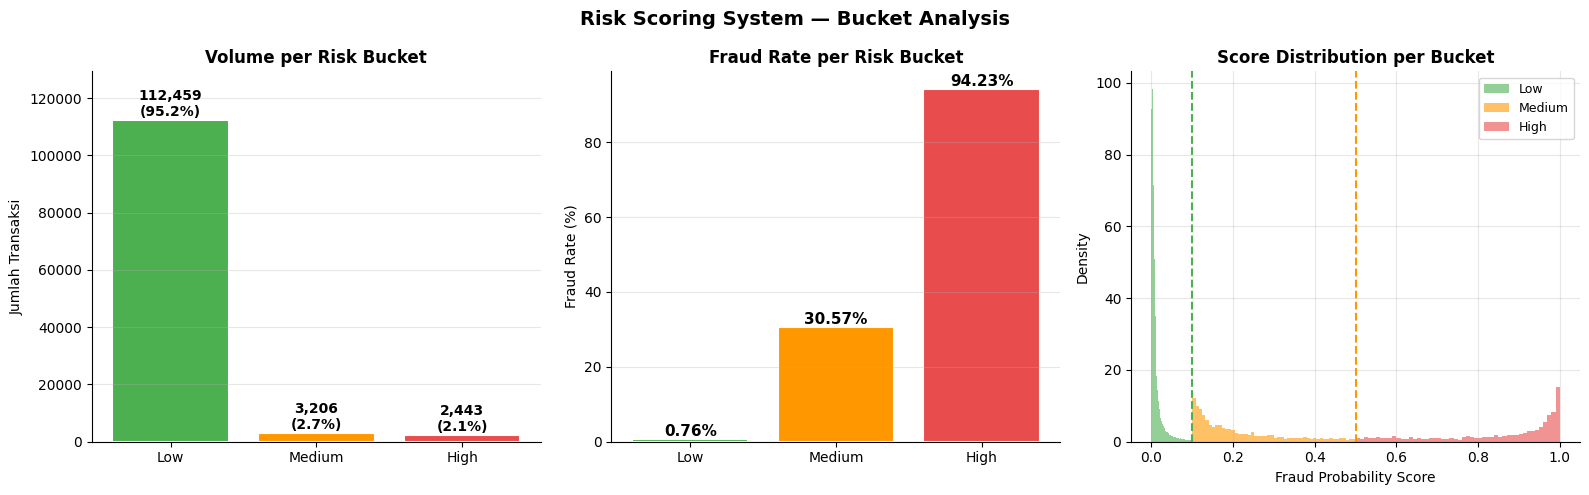

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

bucket_order  = ['Low', 'Medium', 'High']
bucket_colors = {'Low': '#4CAF50', 'Medium': '#FF9800', 'High': '#E84C4C'}

# --- Volume per bucket ---
ax = axes[0]
counts = bucket_df['risk_bucket'].value_counts().reindex(bucket_order)
bars = ax.bar(bucket_order, counts.values,
              color=[bucket_colors[b] for b in bucket_order],
              edgecolor='white', linewidth=1.5)
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+200,
            f'{v:,}\n({v/len(bucket_df)*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', fontsize=10)
ax.set_title('Volume per Risk Bucket', fontweight='bold')
ax.set_ylabel('Jumlah Transaksi')
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Fraud rate per bucket ---
ax = axes[1]
fraud_rates = bucket_df.groupby('risk_bucket')['y_true'].mean().reindex(bucket_order) * 100
bars = ax.bar(bucket_order, fraud_rates.values,
              color=[bucket_colors[b] for b in bucket_order],
              edgecolor='white', linewidth=1.5)
for bar, v in zip(bars, fraud_rates.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
            f'{v:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax.set_title('Fraud Rate per Risk Bucket', fontweight='bold')
ax.set_ylabel('Fraud Rate (%)')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Score distribution per bucket ---
ax = axes[2]
for bucket in bucket_order:
    sub = bucket_df[bucket_df['risk_bucket'] == bucket]['y_prob']
    ax.hist(sub, bins=50, alpha=0.6, color=bucket_colors[bucket],
            label=bucket, density=True)
ax.axvline(RISK_THRESHOLDS['low_max'],    color='#4CAF50', linestyle='--', linewidth=1.5)
ax.axvline(RISK_THRESHOLDS['medium_max'], color='#FF9800', linestyle='--', linewidth=1.5)
ax.set_xlabel('Fraud Probability Score')
ax.set_ylabel('Density')
ax.set_title('Score Distribution per Bucket', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Risk Scoring System — Bucket Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/06_risk_buckets.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6.5 Expected Value Framework

Hitung **expected value** dari sistem ini dibandingkan dua skenario baseline:
1. **Block semua** — tidak ada transaksi yang lewat
2. **Approve semua** — tidak ada yang diblokir
3. **Model kita** — approve Low, review Medium, block High

In [8]:
if amt_val is not None:
    amt_arr = amt_val.values
else:
    # Pakai rata-rata jika tidak ada
    amt_arr = np.where(y_val.values == 1, avg_fraud_amt, avg_legit_amt)

# Skenario 1: Approve semua (tidak ada model)
fn_all    = y_val.sum()           # semua fraud lolos
cost_all  = (amt_arr[y_val.values == 1] * FN_COST_RATE).sum()

# Skenario 2: Block semua (terlalu ketat)
fp_all      = (y_val == 0).sum()  # semua legit diblokir
cost_block  = (amt_arr[y_val.values == 0] * FP_COST_RATE).sum()

# Skenario 3: Model dengan optimal threshold
y_pred_model = (y_prob >= thr_cost).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val.values, y_pred_model).ravel()

if amt_val is not None:
    mask_fn = (y_pred_model == 0) & (y_val.values == 1)
    mask_fp = (y_pred_model == 1) & (y_val.values == 0)
    fn_cost_model = (amt_arr[mask_fn] * FN_COST_RATE).sum()
    fp_cost_model = (amt_arr[mask_fp] * FP_COST_RATE).sum()
else:
    fn_cost_model = fn * avg_fraud_amt * FN_COST_RATE
    fp_cost_model = fp * avg_legit_amt * FP_COST_RATE

cost_model = fn_cost_model + fp_cost_model + tp * TP_REVIEW_COST

print('=== Expected Value Framework ===')
print(f'\n[Approve All] Total cost: ${cost_all/1e6:.2f}M')
print(f'  → {fn_all:,} fraud lolos, 0 legit diblokir')

print(f'\n[Block All]   Total cost: ${cost_block/1e6:.2f}M')
print(f'  → 0 fraud lolos, {fp_all:,} legit diblokir (revenue lost!)')

print(f'\n[Our Model]   Total cost: ${cost_model/1e6:.2f}M  (thr={thr_cost:.3f})')
print(f'  → {fn} fraud lolos, {fp} legit diblokir')
print(f'  → Fraud caught: {tp}/{y_val.sum()} ({tp/y_val.sum()*100:.1f}%)')

saving_vs_approve_all = cost_all - cost_model
saving_vs_block_all   = cost_block - cost_model
print(f'\nPenghematan vs "Approve All": ${saving_vs_approve_all/1e6:.2f}M')
print(f'Penghematan vs "Block All"  : ${saving_vs_block_all/1e6:.2f}M')

=== Expected Value Framework ===

[Approve All] Total cost: $0.64M
  → 4,133 fraud lolos, 0 legit diblokir

[Block All]   Total cost: $1.53M
  → 0 fraud lolos, 113,975 legit diblokir (revenue lost!)

[Our Model]   Total cost: $0.20M  (thr=0.092)
  → 823 fraud lolos, 2674 legit diblokir
  → Fraud caught: 3310/4133 (80.1%)

Penghematan vs "Approve All": $0.43M
Penghematan vs "Block All"  : $1.32M


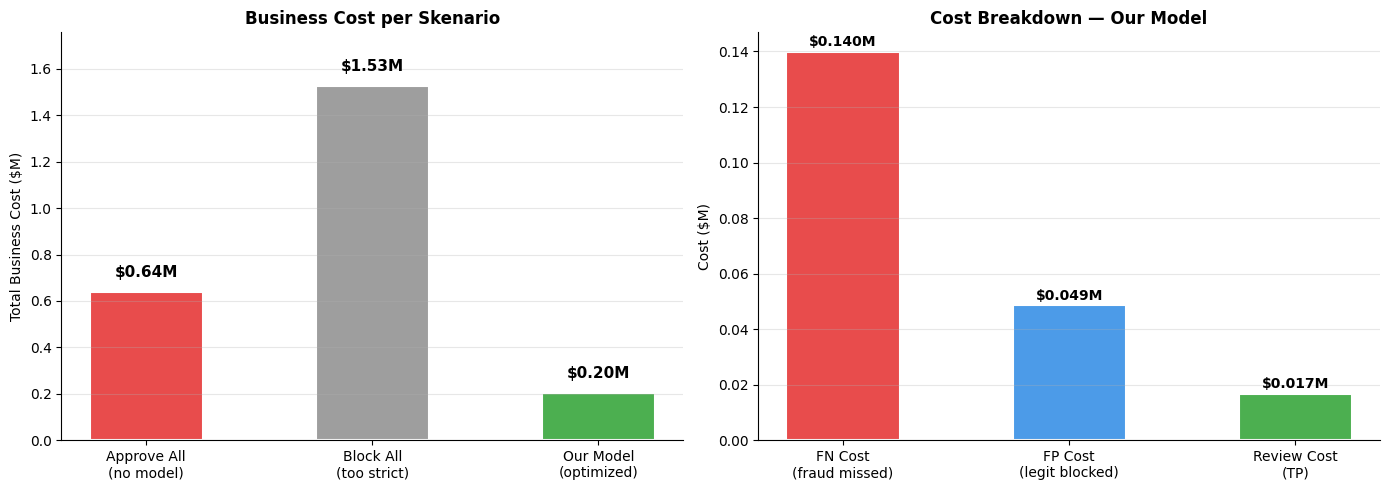

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Cost comparison ---
ax = axes[0]
scenarios = ['Approve All\n(no model)', 'Block All\n(too strict)', 'Our Model\n(optimized)']
costs     = [cost_all/1e6, cost_block/1e6, cost_model/1e6]
sc_colors = ['#E84C4C', '#9E9E9E', '#4CAF50']
bars = ax.bar(scenarios, costs, color=sc_colors, edgecolor='white', linewidth=1.5, width=0.5)
for bar, v in zip(bars, costs):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
            f'${v:.2f}M', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax.set_ylabel('Total Business Cost ($M)')
ax.set_title('Business Cost per Skenario', fontweight='bold')
ax.set_ylim(0, max(costs) * 1.15)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# --- Cost breakdown model ---
ax = axes[1]
breakdown = {
    'FN Cost\n(fraud missed)': fn_cost_model/1e6,
    'FP Cost\n(legit blocked)': fp_cost_model/1e6,
    'Review Cost\n(TP)': tp * TP_REVIEW_COST / 1e6,
}
bd_colors = [FRAUD_COLOR, NONFRAUD_COLOR, '#4CAF50']
bars = ax.bar(breakdown.keys(), breakdown.values(), color=bd_colors,
              edgecolor='white', linewidth=1.5, width=0.5)
for bar, v in zip(bars, breakdown.values()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
            f'${v:.3f}M', ha='center', va='bottom', fontweight='bold', fontsize=10)
ax.set_ylabel('Cost ($M)')
ax.set_title('Cost Breakdown — Our Model', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/06_business_value.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6.6 Final Model Card

In [10]:
final_pred = (y_prob >= thr_cost).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val.values, final_pred).ravel()

model_card = {
    'model_name'         : 'Alto Fraud Detection — LightGBM Baseline',
    'algorithm'          : 'LightGBM (GBDT)',
    'n_features'         : len(feature_cols),
    'training_samples'   : 472432,
    'val_samples'        : len(y_val),
    'fraud_rate_val'     : round(float(y_val.mean()), 4),
    'metrics': {
        'auc_roc'  : round(roc_auc_score(y_val, y_prob), 4),
        'auc_pr'   : round(average_precision_score(y_val, y_prob), 4),
        'f1'       : round(f1_score(y_val, final_pred), 4),
        'precision': round(precision_score(y_val, final_pred), 4),
        'recall'   : round(recall_score(y_val, final_pred), 4),
    },
    'threshold'          : round(float(thr_cost), 4),
    'confusion_matrix'   : {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
    'risk_thresholds'    : RISK_THRESHOLDS,
    'business_cost_model': round(float(cost_model/1e6), 4),
    'saving_vs_no_model' : round(float(saving_vs_approve_all/1e6), 4),
}

model_card_path = '../models/artifacts/model_card.json'
with open(model_card_path, 'w') as f:
    json.dump(model_card, f, indent=2)

print('=== MODEL CARD ===')
print(json.dumps(model_card, indent=2))
print(f'\nSaved → {model_card_path}')

=== MODEL CARD ===
{
  "model_name": "Alto Fraud Detection \u2014 LightGBM Baseline",
  "algorithm": "LightGBM (GBDT)",
  "n_features": 419,
  "training_samples": 472432,
  "val_samples": 118108,
  "fraud_rate_val": 0.035,
  "metrics": {
    "auc_roc": 0.9609,
    "auc_pr": 0.7951,
    "f1": 0.6543,
    "precision": 0.5531,
    "recall": 0.8009
  },
  "threshold": 0.0925,
  "confusion_matrix": {
    "tn": 111301,
    "fp": 2674,
    "fn": 823,
    "tp": 3310
  },
  "risk_thresholds": {
    "low_max": 0.1,
    "medium_max": 0.5
  },
  "business_cost_model": 0.205,
  "saving_vs_no_model": 0.4341
}

Saved → ../models/artifacts/model_card.json


---
## 6.7 Ringkasan

| Aspek | Keputusan |
|-------|----------|
| **Threshold operasional** | Ditentukan oleh minimum business cost, bukan default 0.5 |
| **Risk bucket** | Low (<0.10) → approve, Medium (0.10–0.50) → review, High (>0.50) → block |
| **Penghematan** | Model menghemat jutaan dollar vs tidak ada model sama sekali |
| **Trade-off** | FN masih terjadi — bisa dikurangi dengan menurunkan threshold (terima lebih banyak FP) |

**Next step → Notebook 07: API, Monitoring & Dashboard** — deploy model ke FastAPI endpoint dan buat monitoring drift.